# 01. DENUE OSINT Ingest, Empirical 5D B2B Qualification & Commuter Flow Mapping

End-to-end Open-Source Intelligence (OSINT) ingestion, geospatial filtering, empirical workforce enrichment, multi-criteria machine learning qualification, and interactive Folium visualization centered on **The Coffee — Paseo MS (Silao, Gto.)**.

### OSINT Data Provenance & License Compliance
- **INEGI DENUE (*Términos de Libre Uso MX*):** Establishment directory, 6-digit SCIAN taxonomy, headcount strata (`per_ocu`), WGS84 coordinates, and institutional contact metadata. *Fuente: INEGI. Directorio Estadístico Nacional de Unidades Económicas (DENUE).*
- **INEGI Censos Económicos (SAIC) & IMSS Datos Abiertos (SBC):** Empirical monthly remuneration (`est_monthly_wage_mxn`), university/engineering degree share (`est_degree_share`), and estimated monthly payroll pool (`est_monthly_payroll_mxn`) by 4-digit and 2-digit SCIAN codes in Guanajuato.
- **SICT Datos Viales (TDPA) & OSRM Open Routing:** Annual Average Daily Traffic (`tdpa_total`), light passenger vehicle share, and 7:00–10:00 AM morning peak flow (`K = 0.24`) snapped to physical road geometry via OSRM.
- **OpenStreetMap Overpass API (*ODbL Horizontal Separation*):** Surrounding commercial/institutional POIs queried and persisted as an independent layer (`osm_amenities.parquet`) without mutating DENUE entity records (`docs/LICENSE_COMPLIANCE.md`).
- **Stage 02 Handoff Contract:** Persists deduplicated, schema-validated Parquet extracts to `data/raw/` and `data/processed/` ready for `02_entity_resolution.ipynb`.

In [1]:
# MIGRATES TO: src/mx_osint/config.py::Settings
from pathlib import Path
from pydantic import Field, model_validator
from pydantic_settings import BaseSettings, SettingsConfigDict

PASEO_MS_LAT: float = 20.953791996685183
PASEO_MS_LON: float = -101.41605322904304


class Settings(BaseSettings):
    model_config = SettingsConfigDict(
        env_file=(".env", "../.env"), env_file_encoding="utf-8", extra="ignore"
    )
    INEGI_STATE_CODE: str = Field(default="11", description="INEGI State Code (01-32)")
    TARGET_LAT: float = Field(default=PASEO_MS_LAT, description="Latitude center (The Coffee Paseo MS)")
    TARGET_LON: float = Field(default=PASEO_MS_LON, description="Longitude center (The Coffee Paseo MS)")
    RADIUS_KM: float = Field(default=5.0, description="Catchment radius in km")
    MIN_EMPLOYEES_STRATA: str = Field(default="11 a 30 personas", description="Minimum employee strata")
    DDG_SLEEP_SEC: float = Field(default=2.0, description="DDG rate limit sleep")
    CACHE_DIR: Path = Field(default=Path("data/raw"), description="Local raw cache directory")
    PROCESSED_DIR: Path = Field(default=Path("data/processed"), description="Processed output directory")

    @model_validator(mode="after")
    def enforce_paseo_ms_coordinates(self) -> "Settings":
        self.TARGET_LAT = PASEO_MS_LAT
        self.TARGET_LON = PASEO_MS_LON
        return self


settings = Settings()
print("📍 Centro OSINT confirmado: The Coffee — Paseo MS, Silao")
print(f"   Lat:   {settings.TARGET_LAT:.8f}")
print(f"   Lon:   {settings.TARGET_LON:.8f}")
print(f"   Radio: {settings.RADIUS_KM} km | Estrato mín: '{settings.MIN_EMPLOYEES_STRATA}'")

📍 Centro OSINT confirmado: The Coffee — Paseo MS, Silao
   Lat:   20.95379200
   Lon:   -101.41605323
   Radio: 5.0 km | Estrato mín: '11 a 30 personas'


In [2]:
# MIGRATES TO: src/mx_osint/models/denue.py::DENUEBusiness
from datetime import datetime
from pathlib import Path
import random
from typing import Optional
import polars as pl
from pydantic import BaseModel, ConfigDict, Field, field_validator

STRATA_ORDER: list[str] = [
    "0 a 5 personas",
    "6 a 10 personas",
    "11 a 30 personas",
    "31 a 50 personas",
    "51 a 100 personas",
    "101 a 250 personas",
    "251 y más personas",
]

STRATA_HEADCOUNT_MIDPOINT: dict[str, float] = {
    "0 a 5 personas": 3.0,
    "6 a 10 personas": 8.0,
    "11 a 30 personas": 20.0,
    "31 a 50 personas": 40.0,
    "51 a 100 personas": 75.0,
    "101 a 250 personas": 175.0,
    "251 y más personas": 350.0,
}


class DENUEBusiness(BaseModel):
    """Schema for a single DENUE business record after ingest and cleaning."""
    model_config = ConfigDict(str_strip_whitespace=True)

    row_id: str = Field(..., description="Unique row identifier from INEGI")
    denue_id: str = Field(..., description="CLEE unique business ID")
    business_name: str = Field(..., min_length=1, description="Commercial name")
    legal_name: Optional[str] = Field(None, description="Legal entity name (razón social)")
    scian_code: str = Field(..., pattern=r"^\d{6}$", description="6-digit SCIAN code")
    scian_description: str = Field(..., min_length=1, description="SCIAN activity description")
    employee_strata: str = Field(..., description="Employee range category")

    lat: float = Field(..., ge=-90, le=90, description="Latitude")
    lon: float = Field(..., ge=-180, le=180, description="Longitude")
    street_type: Optional[str] = None
    street_name: Optional[str] = None
    street_number_ext: Optional[str] = None
    postal_code: Optional[str] = Field(None, pattern=r"^\d{5}$")
    state: str = Field(..., min_length=1)
    municipality: str = Field(..., min_length=1)
    locality: Optional[str] = None

    phone: Optional[str] = None
    email: Optional[str] = None
    website: Optional[str] = None
    registration_date: Optional[str] = None

    @field_validator("email")
    @classmethod
    def validate_email(cls, v: Optional[str]) -> Optional[str]:
        return v if (v and "@" in v) else None

    @field_validator("website")
    @classmethod
    def validate_website(cls, v: Optional[str]) -> Optional[str]:
        return v if (v and (v.startswith("http") or v.startswith("www"))) else None


class DENUEDataset(BaseModel):
    """Metadata summary schema for a filtered DENUE extract."""
    version: str = Field(default="2026.10")
    state_code: str = Field(..., pattern=r"^\d{2}$")
    radius_km: float = Field(..., gt=0)
    target_lat: float
    target_lon: float
    total_records: int = Field(..., ge=0)
    records_with_email: int = Field(..., ge=0)
    records_with_phone: int = Field(..., ge=0)
    records_with_website: int = Field(..., ge=0)
    created_at: datetime = Field(default_factory=datetime.now)

    @property
    def email_coverage(self) -> float:
        return (self.records_with_email / self.total_records * 100) if self.total_records > 0 else 0.0


def generate_synthetic_denue_fixture(
    output_path: Path = Path("data/raw/synthetic_denue_fallback.parquet"),
    n_rows: int = 500,
) -> Path:
    """Generates offline fallback DENUE sample centered on Paseo MS without mutating test fixtures."""
    random.seed(42)
    scian_codes = [
        ("621111", "Consultorios de medicina general del sector privado"),
        ("541110", "Bufetes jurídicos"),
        ("541211", "Servicios de contabilidad y auditoría"),
        ("541330", "Servicios de ingeniería"),
        ("541510", "Servicios de diseño de sistemas de cómputo"),
        ("336390", "Fabricación de otras partes para vehículos automotrices"),
        ("721111", "Hoteles con otros servicios integrados"),
        ("522110", "Banca múltiple"),
    ]
    rows = []
    for i in range(n_rows):
        scian_code, scian_desc = random.choice(scian_codes)
        rows.append({
            "row_id": str(9000000 + i),
            "denue_id": f"11037{i:020d}",
            "business_name": f"CORPORATIVO SINTETICO {i:04d}",
            "legal_name": f"CORPORATIVO SINTETICO {i:04d} SA DE CV",
            "scian_code": scian_code,
            "scian_description": scian_desc,
            "employee_strata": random.choice(STRATA_ORDER[2:]),
            "street_type": "BOULEVARD",
            "street_name": "EMILIANO ZAPATA",
            "street_number_ext": str(random.randint(1, 999)),
            "postal_code": "36100",
            "state": "GUANAJUATO",
            "municipality": "Silao de la Victoria",
            "locality": "Silao de la Victoria",
            "phone": f"472{random.randint(1000000, 9999999)}" if random.random() < 0.6 else None,
            "email": f"contacto{i}@empresa{i}.com.mx" if random.random() < 0.5 else None,
            "website": f"https://www.empresa{i}.com.mx" if random.random() < 0.35 else None,
            "registration_date": "2021-06",
            "lat": PASEO_MS_LAT + random.gauss(0, 0.015),
            "lon": PASEO_MS_LON + random.gauss(0, 0.015),
        })
    output_path.parent.mkdir(parents=True, exist_ok=True)
    pl.DataFrame(rows).write_parquet(output_path)
    return output_path

In [3]:
# MIGRATES TO: src/mx_osint/sources/denue_loader.py::read_denue_csv
import hashlib
import io
import math
import shutil
import zipfile
from pathlib import Path
import polars as pl
import requests
from loguru import logger
from tenacity import retry, stop_after_attempt, wait_exponential

DENUE_COLUMN_MAPPING: dict[str, str] = {
    "id": "row_id",
    "clee": "denue_id",
    "nom_estab": "business_name",
    "raz_social": "legal_name",
    "codigo_act": "scian_code",
    "nombre_act": "scian_description",
    "per_ocu": "employee_strata",
    "tipo_vial": "street_type",
    "nom_vial": "street_name",
    "numero_ext": "street_number_ext",
    "cod_postal": "postal_code",
    "entidad": "state",
    "municipio": "municipality",
    "localidad": "locality",
    "telefono": "phone",
    "correoelec": "email",
    "www": "website",
    "fecha_alta": "registration_date",
    "latitud": "lat",
    "longitud": "lon",
    "cve_ent": "cve_ent",
    "cve_mun": "cve_mun",
}


@retry(stop=stop_after_attempt(3), wait=wait_exponential(multiplier=1, min=2, max=10))
def download_denue_state(state_code: str, cache_dir: Path) -> Path:
    """Downloads DENUE state zip package from official INEGI portal with retry and caching."""
    cache_dir.mkdir(parents=True, exist_ok=True)
    target_file = cache_dir / f"denue_{state_code}_csv.zip"
    alt_cache = Path("../data/raw") / f"denue_{state_code}_csv.zip"
    nb_cache = Path("notebooks/data/raw") / f"denue_{state_code}_csv.zip"

    for candidate in (target_file, alt_cache, nb_cache):
        if candidate.exists() and candidate.stat().st_size > 0:
            logger.info(f"Cache hit for state {state_code}: {candidate}")
            return candidate

    url = f"https://www.inegi.org.mx/contenidos/masiva/denue/denue_{state_code}_csv.zip"
    logger.info(f"Downloading DENUE state {state_code} from {url}...")
    response = requests.get(url, stream=True, timeout=60)
    response.raise_for_status()

    hasher = hashlib.sha256()
    with open(target_file, "wb") as f:
        for chunk in response.iter_content(chunk_size=65536):
            if chunk:
                f.write(chunk)
                hasher.update(chunk)
    logger.info(f"Saved {target_file} (SHA256: {hasher.hexdigest()[:12]})")
    return target_file


def read_denue_csv(zip_path: Path) -> pl.DataFrame:
    """Reads INEGI DENUE zip CSV with latin1 decoding, type normalization, column pruning, and CLEE deduplication."""
    with zipfile.ZipFile(zip_path, "r") as zf:
        data_files = [
            f for f in zf.namelist()
            if f.startswith("conjunto_de_datos/") and f.endswith(".csv")
        ]
        if not data_files:
            raise ValueError(f"No data CSV found in {zip_path}.")
        data_file = data_files[0]
        logger.info(f"Reading DENUE data file: {data_file}")
        with zf.open(data_file) as f:
            raw_bytes = f.read()

    df = pl.read_csv(
        io.BytesIO(raw_bytes),
        encoding="latin1",
        separator=",",
        quote_char='"',
        has_header=True,
        infer_schema_length=10000,
        ignore_errors=True,
        null_values=["", "NA", "N/A", "NULL"],
    )

    rename_dict = {old: new for old, new in DENUE_COLUMN_MAPPING.items() if old in df.columns}
    missing = {"lat", "lon", "business_name"} - set(rename_dict.values())
    if missing:
        raise ValueError(f"Critical columns missing: {missing}")

    df = df.rename(rename_dict)
    keep_cols = [c for c in DENUE_COLUMN_MAPPING.values() if c in df.columns]
    df = df.select(keep_cols)

    str_cols = [
        c for c in [
            "row_id", "denue_id", "business_name", "legal_name", "scian_description",
            "employee_strata", "email", "website", "phone", "street_type", "street_name",
            "street_number_ext", "postal_code", "state", "municipality", "locality",
        ]
        if c in df.columns
    ]

    raw_count = len(df)
    df = (
        df.with_columns([
            pl.col("scian_code").cast(pl.Utf8, strict=False).str.strip_chars().str.zfill(6),
            pl.col("lat").cast(pl.Utf8, strict=False).str.replace(",", ".").str.strip_chars().cast(pl.Float64, strict=False),
            pl.col("lon").cast(pl.Utf8, strict=False).str.replace(",", ".").str.strip_chars().cast(pl.Float64, strict=False),
            *[pl.col(c).cast(pl.Utf8, strict=False).str.strip_chars() for c in str_cols],
        ])
        .filter(
            pl.col("lat").is_not_null()
            & pl.col("lon").is_not_null()
            & pl.col("lat").is_between(-90, 90)
            & pl.col("lon").is_between(-180, 180)
            & pl.col("business_name").is_not_null()
            & (pl.col("business_name") != "")
        )
        .unique(subset=["denue_id"], keep="first", maintain_order=True)
    )

    logger.info(
        f"✅ Loaded & deduplicated DENUE DataFrame: {len(df):,} unique valid rows "
        f"(removed {raw_count - len(df):,} invalid/duplicate rows) × {len(df.columns)} standardized columns"
    )
    return df


def filter_by_radius(df: pl.DataFrame, target_lat: float, target_lon: float, radius_km: float) -> pl.DataFrame:
    """Vectorized Haversine distance calculation and radius filtering using Polars expression API."""
    r_km = 6371.0
    rad = math.pi / 180.0
    t_lat_rad = target_lat * rad

    lat_col = pl.col("lat").cast(pl.Float64, strict=False)
    lon_col = pl.col("lon").cast(pl.Float64, strict=False)

    dlat = (lat_col - target_lat) * rad
    dlon = (lon_col - target_lon) * rad

    a = (dlat / 2.0).sin().pow(2) + math.cos(t_lat_rad) * (lat_col * rad).cos() * (dlon / 2.0).sin().pow(2)
    dist_expr = (2.0 * a.sqrt().arcsin() * r_km).alias("distance_km")

    return (
        df.with_columns(dist_expr)
        .filter(pl.col("distance_km") <= radius_km)
        .sort("distance_km")
    )


def filter_by_strata(df: pl.DataFrame, min_strata: str) -> pl.DataFrame:
    """Filters records by employee strata threshold or higher."""
    if min_strata not in STRATA_ORDER:
        raise ValueError(f"Invalid strata '{min_strata}'. Must be one of {STRATA_ORDER}")
    allowed = STRATA_ORDER[STRATA_ORDER.index(min_strata):]
    return df.filter(pl.col("employee_strata").is_in(allowed))


def persist_stage1_extract(
    df: pl.DataFrame,
    state_code: str,
    radius_km: float,
    raw_dir: Path,
    processed_dir: Path,
) -> tuple[Path, Path]:
    """
    Persists Stage-01 enriched DENUE extract to processed_dir and writes the
    BusinessEntity-compatible handoff parquet to raw_dir for Stage 02 (02_entity_resolution.ipynb).
    """
    filename = f"denue_state_{state_code}_radius_{int(radius_km)}km.parquet"
    processed_dir.mkdir(parents=True, exist_ok=True)
    raw_dir.mkdir(parents=True, exist_ok=True)

    proc_path = processed_dir / filename
    df.write_parquet(proc_path)

    # Stage-02 / Stage-03 Handoff Schema (includes BusinessEntity contract fields expected by 02 & 03 notebooks)
    handoff_df = df.with_columns([
        pl.col("row_id").alias("id"),
        pl.col("denue_id").alias("clee"),
        pl.col("business_name").alias("nombre_estab"),
        pl.col("legal_name").alias("raz_social"),
        pl.col("scian_code").alias("codigo_act"),
        pl.col("scian_description").alias("nombre_act"),
        pl.col("employee_strata").alias("per_ocu"),
        pl.col("phone").alias("telefono"),
        pl.col("email").alias("correoelec"),
        pl.col("website").alias("www"),
        (pl.col("cve_ent").cast(pl.Utf8).str.zfill(2) if "cve_ent" in df.columns else pl.lit(state_code)).alias("ent"),
        (pl.col("cve_mun").cast(pl.Utf8).str.zfill(3) if "cve_mun" in df.columns else pl.col("municipality")).alias("mun"),
        pl.col("registration_date").alias("fecha_alta"),
    ])
    raw_path = raw_dir / filename
    handoff_df.write_parquet(raw_path)

    # Sync between /app/data and /app/notebooks/data so CLI (`make resolve`) and Jupyter Lab share exact state
    for peer_root in (Path(".."), Path("notebooks")):
        if (peer_root / "data").exists():
            peer_raw = peer_root / "data" / "raw" / filename
            peer_proc = peer_root / "data" / "processed" / filename
            peer_raw.parent.mkdir(parents=True, exist_ok=True)
            peer_proc.parent.mkdir(parents=True, exist_ok=True)
            if peer_raw.resolve() != raw_path.resolve():
                shutil.copy2(raw_path, peer_raw)
            if peer_proc.resolve() != proc_path.resolve():
                shutil.copy2(proc_path, peer_proc)

    logger.info(f"✅ Persisted Stage-01 processed extract ({len(df):,} rows) -> {proc_path}")
    logger.info(f"✅ Persisted Stage-02 handoff extract ({len(handoff_df):,} rows) -> {raw_path}")
    return proc_path, raw_path

In [4]:
# MIGRATES TO: src/mx_osint/scoring/b2b_qualifier.py::qualify_b2b
import polars as pl
from loguru import logger

SCIAN_SECTOR_MAP: dict[str, str] = {
    # ─── ✅ DIRECT B2B TARGETS ───
    "51": "information_media",
    "52": "financial_services",
    "53": "real_estate",
    "54": "professional_services",
    "55": "corporate_offices",
    "56": "business_support",
    "62": "healthcare",
    # ─── ⚠️ PARTIAL TARGETS ───
    "23": "construction",
    "31": "manufacturing",
    "32": "manufacturing",
    "33": "manufacturing",
    "43": "wholesale_trade",
    "48": "transportation",
    "49": "transportation",
    "61": "education",
    "72": "hospitality",
    # ─── ❌ NON-TARGETS ───
    "11": "agriculture",
    "21": "mining",
    "22": "utilities",
    "46": "retail_trade",
    "71": "entertainment",
    "81": "other_services",
    "93": "government",
}

TARGET_SECTORS: set[str] = {
    "professional_services", "corporate_offices", "financial_services",
    "information_media", "real_estate", "business_support", "healthcare",
}

PARTIAL_SECTORS: set[str] = {
    "manufacturing", "hospitality", "education", "construction",
    "wholesale_trade", "transportation",
}


def qualify_b2b(df: pl.DataFrame) -> pl.DataFrame:
    """
    Classifies DENUE records into 'target', 'partial', or 'no_target' using 2-digit SCIAN prefixes
    and excludes public-sector institutions and food/beverage retailers from private B2B outreach.
    """
    sector_lookup = pl.DataFrame({
        "scian_sector_code": list(SCIAN_SECTOR_MAP.keys()),
        "b2b_sector": list(SCIAN_SECTOR_MAP.values()),
    })

    is_public_entity = (
        pl.col("scian_description").fill_null("").str.to_lowercase().str.contains("sector público|asistencia social")
        | pl.col("email").fill_null("").str.to_lowercase().str.contains(r"\.gob\.mx")
        | pl.col("website").fill_null("").str.to_lowercase().str.contains(r"\.gob\.mx")
        | (
            pl.col("b2b_sector").is_in(["education", "healthcare"])
            & pl.col("business_name").fill_null("").str.to_lowercase().str.contains(
                "públic|public|oficial|federal|estatal|municipal|imss|issste|isapeg|dif |secretar"
            )
        )
    )

    df_enriched = (
        df.with_columns(
            pl.col("scian_code").cast(pl.Utf8).str.zfill(6).str.slice(0, 2).alias("scian_sector_code")
        )
        .join(sector_lookup, on="scian_sector_code", how="left")
        .with_columns(pl.col("b2b_sector").fill_null("unclassified"))
        .with_columns(
            pl.when(pl.col("b2b_sector").is_in(TARGET_SECTORS))
            .then(pl.lit("target"))
            .when(pl.col("b2b_sector").is_in(PARTIAL_SECTORS))
            .then(pl.lit("partial"))
            .otherwise(pl.lit("no_target"))
            .alias("b2b_status")
        )
        .with_columns(
            pl.when(is_public_entity)
            .then(pl.lit("no_target"))
            .when(
                (pl.col("b2b_sector") == "hospitality")
                & (~pl.col("scian_code").str.starts_with("721"))  # Keep 721 (Hotels), exclude 722 (Restaurants/Bars)
            )
            .then(pl.lit("no_target"))
            .otherwise(pl.col("b2b_status"))
            .alias("b2b_status")
        )
    )

    logger.info("✅ SCIAN B2B qualification complete (public sector & food/bev retail excluded).")
    return df_enriched

In [5]:
# MIGRATES TO: src/mx_osint/sources/osm_loader.py::query_osm_amenities
from pathlib import Path
import polars as pl
import requests
from loguru import logger

OVERPASS_ENDPOINTS: list[str] = [
    "https://lz4.overpass-api.de/api/interpreter",
    "https://overpass-api.de/api/interpreter",
    "https://overpass.kumi.systems/api/interpreter",
]


def query_osm_amenities(
    lat: float,
    lon: float,
    radius_km: float,
    cache_path: Path = Path("data/processed/osm_amenities.parquet"),
) -> pl.DataFrame:
    """
    Queries OpenStreetMap Overpass API for commercial/institutional amenities near target location.
    Persisted separately to maintain strict ODbL horizontal separation from INEGI DENUE records.
    """
    if cache_path.exists() and cache_path.stat().st_size > 0:
        df_cached = pl.read_parquet(cache_path)
        logger.info(f"Cache hit for ODbL-separated OSM layer: {cache_path} ({len(df_cached):,} POIs)")
        return df_cached

    radius_m = int(radius_km * 1000)
    query = f"""
    [out:json][timeout:45];
    (
      node["amenity"~"^(cafe|restaurant|bank|pharmacy|hospital|clinic|school|university)$"](around:{radius_m},{lat},{lon});
      way["amenity"~"^(cafe|restaurant|bank|pharmacy|hospital|clinic|school|university)$"](around:{radius_m},{lat},{lon});
      node["office"](around:{radius_m},{lat},{lon});
      way["office"](around:{radius_m},{lat},{lon});
      node["shop"~"^(supermarket|convenience|mall)$"](around:{radius_m},{lat},{lon});
      way["shop"~"^(supermarket|convenience|mall)$"](around:{radius_m},{lat},{lon});
    );
    out center;
    """

    headers = {
        "User-Agent": "MexicoCommercialOSINT/1.0 (ODbL-Layer; Silao, Gto)",
        "Accept": "application/json",
    }

    elements = []
    for endpoint in OVERPASS_ENDPOINTS:
        try:
            logger.info(f"Querying OSM Overpass API ({endpoint}) around ({lat:.5f}, {lon:.5f}), radius={radius_km}km...")
            response = requests.post(endpoint, data={"data": query}, headers=headers, timeout=45)
            response.raise_for_status()
            elements = response.json().get("elements", [])
            if elements:
                break
        except Exception as e:
            logger.warning(f"Overpass mirror {endpoint} failed ({e}), trying next...")

    records = []
    for elem in elements:
        lat_val = elem.get("lat") or elem.get("center", {}).get("lat")
        lon_val = elem.get("lon") or elem.get("center", {}).get("lon")
        if lat_val and lon_val:
            tags = elem.get("tags", {})
            records.append({
                "osm_id": str(elem["id"]),
                "type": elem["type"],
                "lat": float(lat_val),
                "lon": float(lon_val),
                "name": tags.get("name", ""),
                "amenity": tags.get("amenity", ""),
                "office": tags.get("office", ""),
                "shop": tags.get("shop", ""),
            })

    if not records:
        return pl.DataFrame()

    df_osm = pl.DataFrame(records).unique(subset=["osm_id"], keep="first")
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    df_osm.write_parquet(cache_path)
    logger.info(f"✅ Persisted {len(df_osm):,} unique OSM amenities -> {cache_path}")
    return df_osm

In [6]:
# MIGRATES TO: src/mx_osint/scoring/empirical_adaboost_scorer.py::calculate_critic_and_adaboost_weights
import math
import numpy as np
import polars as pl
import requests
from loguru import logger
from sklearn.ensemble import AdaBoostClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier

# ═══════════════════════════════════════════════════════════════════════════
# 1. SICT DATOS VIALES: 7:00 - 10:00 AM COMMUTE CORRIDORS (SILAO, GTO.)
# ═══════════════════════════════════════════════════════════════════════════
MORNING_COMMUTE_CORRIDORS: list[dict] = [
    {
        "id": "fed45_norte",
        "name": "Corredor Fed. 45 Norte (León / Puerto Interior ➔ Silao / Paseo MS)",
        "tdpa_total": 68500,
        "pct_light_cars": 0.72,
        "morning_share": 0.24,  # ~11,837 commuter cars (7-10 AM)
        "color": "#d62728",
        "waypoints": [
            (20.9785, -101.4485),
            (20.9685, -101.4390),
            (20.9575, -101.4265),
            (settings.TARGET_LAT, settings.TARGET_LON),
        ],
        "gauge_lat": 20.9685,
        "gauge_lon": -101.4390,
    },
    {
        "id": "fed45_sur",
        "name": "Corredor Fed. 45 Sur (Irapuato / FIPASI ➔ Silao / Paseo MS)",
        "tdpa_total": 54200,
        "pct_light_cars": 0.68,
        "morning_share": 0.24,  # ~8,845 commuter cars (7-10 AM)
        "color": "#ff7f0e",
        "waypoints": [
            (20.9220, -101.4235),
            (20.9385, -101.4275),
            (20.9505, -101.4252),
            (settings.TARGET_LAT, settings.TARGET_LON),
        ],
        "gauge_lat": 20.9250,
        "gauge_lon": -101.4245,
    },
    {
        "id": "fed110_este",
        "name": "Corredor Fed. 110 / Blvd. GM (Gto. Capital ➔ Paseo MS / Colinas)",
        "tdpa_total": 34800,
        "pct_light_cars": 0.81,
        "morning_share": 0.24,  # ~6,765 commuter cars (7-10 AM)
        "color": "#fdae61",
        "waypoints": [
            (20.9560, -101.3860),
            (20.9515, -101.4020),
            (settings.TARGET_LAT, settings.TARGET_LON),
        ],
        "gauge_lat": 20.9515,
        "gauge_lon": -101.4020,
    },
    {
        "id": "zapata_local",
        "name": "Arteria Local Blvd. Emiliano Zapata (Silao Centro ➔ Paseo MS ➔ Parque Ind.)",
        "tdpa_total": 28400,
        "pct_light_cars": 0.85,
        "morning_share": 0.24,  # ~5,794 commuter cars (7-10 AM)
        "color": "#00b4d8",
        "waypoints": [
            (20.9430, -101.4270),
            (20.9495, -101.4210),
            (settings.TARGET_LAT, settings.TARGET_LON),
            (20.9682, -101.4243),
        ],
        "gauge_lat": 20.9495,
        "gauge_lon": -101.4210,
    },
]

# ═══════════════════════════════════════════════════════════════════════════
# 2. EMPIRICAL WAGE & EDUCATION TABLE (INEGI CENSOS ECONÓMICOS + IMSS SBC GTO)
# ═══════════════════════════════════════════════════════════════════════════
INEGI_IMSS_SCIAN_WAGES_MXN: dict[str, dict[str, float]] = {
    # 4-Digit High-Value Subsectors (Bajío Industrial & Corporate Corridor)
    "3361": {"monthly_wage_mxn": 34500.0, "deg_share": 0.42},  # OEM Automotive Assembly
    "3363": {"monthly_wage_mxn": 26800.0, "deg_share": 0.35},  # Tier-1 Auto Parts & Engineering
    "3364": {"monthly_wage_mxn": 32000.0, "deg_share": 0.48},  # Aerospace Manufacturing
    "3254": {"monthly_wage_mxn": 28500.0, "deg_share": 0.45},  # Pharmaceuticals & Biotech
    "5221": {"monthly_wage_mxn": 29400.0, "deg_share": 0.78},  # Banca Múltiple (Commercial Banks)
    "5413": {"monthly_wage_mxn": 27200.0, "deg_share": 0.82},  # Engineering & Testing Labs
    "5415": {"monthly_wage_mxn": 33100.0, "deg_share": 0.88},  # IT, Software & Systems Design
    "5416": {"monthly_wage_mxn": 26500.0, "deg_share": 0.80},  # Management & HR Consulting
    "6221": {"monthly_wage_mxn": 24800.0, "deg_share": 0.70},  # General & Specialty Hospitals
    "7211": {"monthly_wage_mxn": 16500.0, "deg_share": 0.28},  # Business Hotels
    # 2-Digit Sector Fallbacks (Guanajuato Average)
    "55":   {"monthly_wage_mxn": 36000.0, "deg_share": 0.85},  # Corporate Offices
    "52":   {"monthly_wage_mxn": 25200.0, "deg_share": 0.72},  # Financial Services / SOFOM
    "54":   {"monthly_wage_mxn": 23800.0, "deg_share": 0.75},  # Professional Services
    "51":   {"monthly_wage_mxn": 22400.0, "deg_share": 0.65},  # Telecom & Media
    "62":   {"monthly_wage_mxn": 19500.0, "deg_share": 0.60},  # Clinics & Healthcare
    "33":   {"monthly_wage_mxn": 18900.0, "deg_share": 0.26},  # Metal/Machinery Manufacturing
    "32":   {"monthly_wage_mxn": 17200.0, "deg_share": 0.22},  # Chemical/Plastics Manufacturing
    "56":   {"monthly_wage_mxn": 15800.0, "deg_share": 0.30},  # Business Support & Staffing
    "43":   {"monthly_wage_mxn": 16400.0, "deg_share": 0.28},  # Wholesale Trade (B2B)
    "48":   {"monthly_wage_mxn": 16900.0, "deg_share": 0.20},  # Logistics & Freight Transport
    "61":   {"monthly_wage_mxn": 15200.0, "deg_share": 0.85},  # Education
    "93":   {"monthly_wage_mxn": 14800.0, "deg_share": 0.65},  # Government
    "31":   {"monthly_wage_mxn": 12400.0, "deg_share": 0.14},  # Traditional Food/Apparel Mfg
    "46":   {"monthly_wage_mxn": 10800.0, "deg_share": 0.15},  # Retail Trade
}


def fetch_osrm_corridor_geometry(waypoints: list[tuple[float, float]]) -> list[tuple[float, float]]:
    """Snaps corridor waypoints to physical road geometry via OSRM (falls back to waypoints if offline)."""
    coords_str = ";".join(f"{lon},{lat}" for lat, lon in waypoints)
    url = f"https://router.project-osrm.org/route/v1/driving/{coords_str}?overview=full&geometries=geojson"
    try:
        resp = requests.get(url, headers={"User-Agent": "MexicoCommercialOSINT/1.0"}, timeout=6)
        resp.raise_for_status()
        raw_coords = resp.json()["routes"][0]["geometry"]["coordinates"]
        return [(float(lat), float(lon)) for lon, lat in raw_coords]
    except Exception as e:
        logger.warning(f"OSRM corridor fallback to waypoints ({e})")
        return waypoints


def build_corridor_geometries() -> tuple[list[dict], list[tuple[float, float, float]]]:
    """Builds road-snapped SICT 7:00-10:00 AM corridors and sampled intensity nodes."""
    enriched = []
    traffic_nodes: list[tuple[float, float, float]] = []
    max_morning_cars = max(
        c["tdpa_total"] * c["pct_light_cars"] * c["morning_share"] for c in MORNING_COMMUTE_CORRIDORS
    )

    for corr in MORNING_COMMUTE_CORRIDORS:
        morning_cars = int(corr["tdpa_total"] * corr["pct_light_cars"] * corr["morning_share"])
        norm_intensity = morning_cars / max_morning_cars
        geometry = fetch_osrm_corridor_geometry(corr["waypoints"])

        enriched.append({**corr, "morning_cars": morning_cars, "norm_intensity": norm_intensity, "geometry": geometry})
        step = max(1, len(geometry) // 25)
        for lat, lon in geometry[::step]:
            traffic_nodes.append((lat, lon, norm_intensity))

    return enriched, traffic_nodes


def enrich_empirical_income_and_scholarship(
    df: pl.DataFrame,
    traffic_nodes: list[tuple[float, float, float]],
) -> pl.DataFrame:
    """
    Enriches DENUE records with empirical INEGI/IMSS wage, university degree share,
    estimated monthly payroll pool, and 7:00-10:00 AM SICT commuter exposure.
    """
    wages, deg_shares, payrolls, traffic_exp, corridor_dists = [], [], [], [], []
    r_km, rad = 6371.0, math.pi / 180.0

    for row in df.iter_rows(named=True):
        scian6 = str(row["scian_code"]).zfill(6)
        scian4, scian2 = scian6[:4], scian6[:2]

        emp_data = (
            INEGI_IMSS_SCIAN_WAGES_MXN.get(scian4)
            or INEGI_IMSS_SCIAN_WAGES_MXN.get(scian2)
            or {"monthly_wage_mxn": 13500.0, "deg_share": 0.20}
        )
        wage = emp_data["monthly_wage_mxn"]
        deg = emp_data["deg_share"]

        email_str = (row.get("email") or "").lower()
        has_corp_domain = (
            "@" in email_str
            and not any(free in email_str for free in ["gmail.", "hotmail.", "outlook.", "yahoo.", "live.", "gob.mx", "prodigy."])
        )
        if has_corp_domain:
            wage *= 1.12
            deg = min(0.95, deg + 0.10)

        headcount = STRATA_HEADCOUNT_MIDPOINT.get(row["employee_strata"], 15.0)
        wages.append(round(wage, 0))
        deg_shares.append(round(deg, 2))
        payrolls.append(round(wage * headcount, 0))

        b_lat, b_lon = row["lat"], row["lon"]
        best_corr = 0.0
        min_corr_dist = 99.0
        for n_lat, n_lon, norm_int in traffic_nodes:
            dlat, dlon = (n_lat - b_lat) * rad, (n_lon - b_lon) * rad
            a = math.sin(dlat / 2) ** 2 + math.cos(b_lat * rad) * math.cos(n_lat * rad) * math.sin(dlon / 2) ** 2
            d_km = 2 * math.asin(math.sqrt(a)) * r_km
            if d_km < min_corr_dist:
                min_corr_dist = d_km
            best_corr = max(best_corr, norm_int * math.exp(-d_km / 0.8))

        paseo_prox = max(0.15, 1.0 - (row["distance_km"] / settings.RADIUS_KM))
        traffic_exp.append(round(((0.65 * best_corr) + (0.35 * paseo_prox)) * 10.0, 2))
        corridor_dists.append(round(min_corr_dist, 2))

    return df.with_columns([
        pl.Series("est_monthly_wage_mxn", wages),
        pl.Series("est_degree_share", deg_shares),
        pl.Series("est_monthly_payroll_mxn", payrolls),
        pl.Series("morning_traffic_score", traffic_exp),
        pl.Series("corridor_dist_km", corridor_dists),
    ])


def calculate_critic_and_adaboost_weights(
    df: pl.DataFrame,
) -> tuple[pl.DataFrame, dict[str, dict[str, float]]]:
    """
    Computes CRITIC Objective Weights (unsupervised variance x conflict) and
    AdaBoost Classifier Weights (supervised seed archetypes), producing `b2b_5d_score`.
    """
    status_map = {"target": 1.0, "partial": 0.5, "no_target": 0.1}

    df_feat = df.with_columns([
        pl.when(
            (pl.col("b2b_status") == "partial")
            & (pl.col("est_monthly_wage_mxn") >= 24000)
            & (pl.col("est_degree_share") >= 0.35)
        )
        .then(pl.lit(0.85))
        .otherwise(pl.col("b2b_status").replace_strict(status_map, default=0.1))
        .alias("f_b2b_fit"),
        pl.col("est_monthly_wage_mxn").alias("f_wage_income"),
        (pl.col("est_degree_share") * pl.col("est_monthly_payroll_mxn")).log1p().alias("f_white_collar_mass"),
        pl.col("morning_traffic_score").alias("f_traffic_7_10am"),
        (
            pl.when(pl.col("email").is_not_null() & (pl.col("email") != "")).then(pl.lit(1.0)).otherwise(pl.lit(0.0))
        ).alias("f_contact_ready"),
    ])

    feature_cols = [
        "f_b2b_fit",
        "f_wage_income",
        "f_white_collar_mass",
        "f_traffic_7_10am",
        "f_contact_ready",
    ]

    raw_matrix = df_feat.select(feature_cols).to_numpy()
    scaler = MinMaxScaler()
    norm_matrix = scaler.fit_transform(raw_matrix)

    # Method A: CRITIC Objective Weights (Unsupervised)
    std_devs = np.std(norm_matrix, axis=0, ddof=1)
    corr_matrix = np.nan_to_num(np.corrcoef(norm_matrix, rowvar=False), nan=0.0)
    conflict = np.sum(1.0 - corr_matrix, axis=1)
    critic_info = std_devs * conflict
    critic_weights = critic_info / np.sum(critic_info)

    # Method B: AdaBoost Classifier Weights (Supervised Seed Archetypes)
    y_seed = (
        (df_feat["f_b2b_fit"] >= 0.85)
        & (df_feat["est_monthly_wage_mxn"] >= 22000)
        & (df_feat["distance_km"] <= 3.0)
    ).to_numpy().astype(int)

    ada = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42,
    )
    ada.fit(norm_matrix, y_seed)
    ada_weights = ada.feature_importances_
    ada_probs = ada.predict_proba(norm_matrix)[:, 1]

    critic_scores = (norm_matrix @ critic_weights) * 10.0
    ada_scores = (0.5 * ((norm_matrix @ ada_weights) * 10.0)) + (0.5 * (ada_probs * 10.0))

    weight_comparison = {
        col: {
            "CRITIC_Objective": round(float(cw), 3),
            "AdaBoost_Learned": round(float(aw), 3),
        }
        for col, cw, aw in zip(feature_cols, critic_weights, ada_weights)
    }

    df_out = (
        df_feat.with_columns([
            pl.Series("critic_objective_score", np.round(critic_scores, 2)),
            pl.Series("adaboost_b2b_score", np.round(ada_scores, 2)),
            pl.Series("b2b_5d_score", np.round((critic_scores + ada_scores) / 2.0, 2)),
            (pl.col("f_b2b_fit") == 0.85).alias("is_rescued_partial"),
            (
                pl.lit("$")
                + (pl.col("est_monthly_wage_mxn") / 1000).round(1).cast(pl.Utf8)
                + pl.lit("k MXN/mes (")
                + (pl.col("est_degree_share") * 100).round(0).cast(pl.Int32).cast(pl.Utf8)
                + pl.lit("% Prof.)")
            ).alias("workforce_scholarship_tier"),
        ])
        .drop(feature_cols)
        .sort("b2b_5d_score", descending=True)
    )

    rescued_cnt = df_out.filter(pl.col("is_rescued_partial")).height
    logger.info(f"✅ Empirical 5D Scoring (CRITIC + AdaBoost) complete: {rescued_cnt} high-wage Partial Targets rescued.")
    return df_out, weight_comparison

In [7]:
# MIGRATES TO: src/mx_osint/viz/explorer.py::print_business_metrics
from pathlib import Path
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns


def print_business_metrics(
    df: pl.DataFrame,
    learned_weights: dict[str, dict[str, float]],
) -> None:
    """Prints a single consolidated executive summary of geospatial, empirical OSINT, and B2B metrics."""
    total = len(df)
    if total == 0:
        print("⚠️ Empty DataFrame — check coordinates and radius.")
        return

    def _cov(sub_df: pl.DataFrame, col: str) -> tuple[int, float]:
        if len(sub_df) == 0 or col not in sub_df.columns:
            return 0, 0.0
        cnt = sub_df.filter(pl.col(col).is_not_null() & (pl.col(col) != "")).height
        return cnt, (cnt / len(sub_df)) * 100.0

    targets = df.filter(pl.col("b2b_status") == "target")
    rescued = df.filter(pl.col("is_rescued_partial"))
    partials = df.filter((pl.col("b2b_status") == "partial") & (~pl.col("is_rescued_partial")))
    excluded = df.filter(pl.col("b2b_status") == "no_target")
    actionable = df.filter((pl.col("b2b_status") == "target") | pl.col("is_rescued_partial"))

    print("\n" + "=" * 78)
    print(f"📊 RESUMEN EJECUTIVO OSINT B2B — THE COFFEE PASEO MS (Radio: {settings.RADIUS_KM} km)")
    print("=" * 78)
    print(f"Total unidades económicas únicas (>= '{settings.MIN_EMPLOYEES_STRATA}'): {total:,}")

    avg_dist = df["distance_km"].mean()
    w1 = df.filter(pl.col("distance_km") <= 1.0).height
    w3 = df.filter(pl.col("distance_km") <= 3.0).height
    print(f"\n📍 Distribución Geográfica desde Paseo MS ({settings.TARGET_LAT:.5f}, {settings.TARGET_LON:.5f}):")
    print(f"   • Distancia promedio: {avg_dist:.2f} km | Dentro de 1.0 km: {w1:,} ({w1/total*100:.1f}%) | Dentro de 3.0 km: {w3:,} ({w3/total*100:.1f}%)")

    print("\n🎯 Segmentación B2B (SCIAN Privado + Rescate Empírico INEGI/IMSS):")
    print(f"   • ✅ Targets Directos Privados:          {len(targets):>4,} ({len(targets)/total*100:5.1f}%)")
    print(f"   • 🚀 Rescatados (Alto Salario/Ing.):     {len(rescued):>4,} ({len(rescued)/total*100:5.1f}%)")
    print(f"   • ⚠️ Parciales Estándar:                 {len(partials):>4,} ({len(partials)/total*100:5.1f}%)")
    print(f"   • ❌ No Targets (Comercio/Gob/Rest.):    {len(excluded):>4,} ({len(excluded)/total*100:5.1f}%)")

    em_c, em_p = _cov(actionable, "email")
    ph_c, ph_p = _cov(actionable, "phone")
    wb_c, wb_p = _cov(actionable, "website")
    total_payroll_m = actionable["est_monthly_payroll_mxn"].sum() / 1e6
    print("\n📧 Cobertura de Contacto & Masa Salarial ( Universo Accionable = Directos + Rescatados ):")
    print(f"   • Email: {em_c:>3,} ({em_p:5.1f}%) | Teléfono: {ph_c:>3,} ({ph_p:5.1f}%) | Website: {wb_c:>3,} ({wb_p:5.1f}%)")
    print(f"   • Masa Salarial Mensual Estimada (INEGI/IMSS): ${total_payroll_m:,.1f} M MXN/mes")

    print("\n⚖️ Pesos del Modelo 5D: CRITIC (Objetivo) vs. AdaBoost (Machine Learning):")
    for feat, w_dict in learned_weights.items():
        print(
            f"   • {feat:<22} | CRITIC: {w_dict['CRITIC_Objective']*100:5.1f}%  |  AdaBoost: {w_dict['AdaBoost_Learned']*100:5.1f}%"
        )
    print("=" * 78)


def plot_summary_charts(geo_df: pl.DataFrame, scored_df: pl.DataFrame, output_dir: Path) -> None:
    """Renders 3 diagnostic subplots in a single figure (Distances, Strata, Top B2B Sectors)."""
    output_dir.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

    # 1. Distance Histogram
    distances = geo_df["distance_km"].to_list()
    axes[0].hist(distances, bins=25, color="steelblue", edgecolor="black", alpha=0.75)
    for r, col in [(1.0, "red"), (3.0, "orange"), (5.0, "green")]:
        axes[0].axvline(x=r, color=col, linestyle="--", label=f"{r:.0f} km")
    axes[0].set_title("Distribución de Distancias desde Paseo MS", fontweight="bold")
    axes[0].set_xlabel("Distancia (km)")
    axes[0].set_ylabel("Negocios (Todos los estratos)")
    axes[0].legend()

    # 2. Employee Strata Distribution
    strata_counts = (
        scored_df.group_by("employee_strata")
        .agg(pl.len().alias("count"))
        .to_pandas()
        .set_index("employee_strata")
        .reindex(STRATA_ORDER[2:], fill_value=0)
        .reset_index()
    )
    sns.barplot(
        data=strata_counts,
        x="employee_strata",
        y="count",
        hue="employee_strata",
        palette="YlOrRd",
        legend=False,
        ax=axes[1],
    )
    axes[1].set_title("Negocios por Estrato de Personal", fontweight="bold")
    axes[1].set_xlabel("")
    axes[1].set_ylabel("Negocios")
    axes[1].tick_params(axis="x", rotation=30)

    # 3. B2B Sector Breakdown (Targets & Partials)
    sector_counts = (
        scored_df.filter(pl.col("b2b_status").is_in(["target", "partial"]))
        .group_by(["b2b_sector", "b2b_status"])
        .agg(pl.len().alias("count"))
        .sort("count", descending=True)
        .head(10)
        .to_pandas()
    )
    sns.barplot(
        data=sector_counts,
        x="count",
        y="b2b_sector",
        hue="b2b_status",
        palette={"target": "#2ca02c", "partial": "#ff7f0e"},
        dodge=False,
        ax=axes[2],
    )
    axes[2].set_title("Top Sectores B2B (Target vs Partial)", fontweight="bold")
    axes[2].set_xlabel("Negocios")
    axes[2].set_ylabel("")

    plt.tight_layout()
    chart_path = output_dir / "denue_b2b_diagnostics.png"
    plt.savefig(chart_path, dpi=150, bbox_inches="tight")
    plt.show()

In [8]:
# MIGRATES TO: src/mx_osint/viz/transit_heatmap.py::create_b2b_osint_map
from pathlib import Path
import folium
from folium.plugins import AntPath, HeatMap
from loguru import logger
import polars as pl
import requests


def fetch_osrm_route(
    start_lat: float, start_lon: float, end_lat: float, end_lon: float
) -> list[tuple[float, float]]:
    """Fetches driving route geometry via OSRM between Paseo MS and a prospect."""
    url = (
        f"https://router.project-osrm.org/route/v1/driving/"
        f"{start_lon},{start_lat};{end_lon},{end_lat}?overview=full&geometries=geojson"
    )
    try:
        resp = requests.get(url, headers={"User-Agent": "MexicoCommercialOSINT/1.0"}, timeout=6)
        resp.raise_for_status()
        coords = resp.json()["routes"][0]["geometry"]["coordinates"]
        return [(float(lat), float(lon)) for lon, lat in coords]
    except Exception:
        return []


def create_b2b_osint_map(
    df_scored: pl.DataFrame,
    corridors: list[dict],
    traffic_nodes: list[tuple[float, float, float]],
    osm_df: pl.DataFrame | None = None,
    target_lat: float = settings.TARGET_LAT,
    target_lon: float = settings.TARGET_LON,
    output_path: Path = settings.PROCESSED_DIR / "b2b_5d_morning_transit_heatmap.html",
) -> folium.Map:
    """
    Builds the unified Interactive OSINT B2B Map combining:
      1. Open Base Layers (CartoDB Positron/Dark Matter direct tiles, Esri, Google Traffic)
      2. 1 km and 3 km Catchment Rings
      3. 5D Empirical HeatMap (CRITIC + AdaBoost Ensemble Score + 7:00-10:00 AM SICT Flow)
      4. Animated 7:00-10:00 AM SICT Commute Corridors (AntPath + TDPA Gauges)
      5. OSRM Delivery Routes to Top Actionable B2B Prospects
      6. ODbL-Isolated OpenStreetMap Amenities Layer
      7. Scored B2B Prospect Markers (Direct, Rescued High-Wage, Partial, Excluded)
    """
    m = folium.Map(location=[target_lat, target_lon], zoom_start=14, tiles=None)

    # ─── 1. Base Layers (Direct tile URLs avoid Folium API key warnings) ───
    folium.TileLayer(
        tiles="https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png",
        attr="&copy; OpenStreetMap contributors &copy; CARTO",
        name="🗺️ Mapa Claro Ejecutivo (CARTO Positron)",
        overlay=False,
        control=True,
    ).add_to(m)

    folium.TileLayer(
        tiles="https://{s}.basemaps.cartocdn.com/dark_all/{z}/{x}/{y}{r}.png",
        attr="&copy; OpenStreetMap contributors &copy; CARTO",
        name="🌙 Modo Oscuro (Alto Contraste Calor)",
        overlay=False,
        control=True,
    ).add_to(m)

    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles &copy; Esri",
        name="🏙️ Esri World Street Map",
        overlay=False,
        control=True,
    ).add_to(m)

    folium.TileLayer(
        tiles="https://mt1.google.com/vt/lyrs=m,traffic&x={x}&y={y}&z={z}",
        attr="Google Maps",
        name="🚦 Google Maps (Tráfico en Tiempo Real)",
        max_zoom=20,
        overlay=False,
        control=True,
    ).add_to(m)

    # ─── 2. Catchment Rings (1 km & 3 km) ───
    fg_rings = folium.FeatureGroup(name="⭕ Anillos de Cobertura (1 km y 3 km)", show=True)
    for radius_m, label, ring_color in [
        (1000, "Radio 1 km (Intercepción Directa / Caminable)", "#d62728"),
        (3000, "Radio 3 km (Corredor Urbano / Industrial)", "#ff7f0e"),
    ]:
        folium.Circle(
            location=[target_lat, target_lon],
            radius=radius_m,
            color=ring_color,
            weight=1.8,
            fill=False,
            dash_array="6, 6",
            tooltip=label,
        ).add_to(fg_rings)
    fg_rings.add_to(m)

    # ─── 3. 5D Empirical HeatMap (Ensemble Score + 7-10 AM SICT Arterial Flow) ───
    heat_points: list[list[float]] = []
    for row in df_scored.iter_rows(named=True):
        weight = float(row["b2b_5d_score"]) ** 1.6
        if row["b2b_status"] == "no_target":
            weight *= 0.20
        heat_points.append([row["lat"], row["lon"], weight])

    for t_lat, t_lon, norm_int in traffic_nodes:
        heat_points.append([t_lat, t_lon, norm_int * 8.0])

    HeatMap(
        heat_points,
        name="🔥 Mapa de Calor 5D (Salario INEGI/IMSS + Score Ensemble + Flujo 7-10 AM)",
        min_opacity=0.32,
        max_zoom=16,
        radius=28,
        blur=20,
        gradient={0.25: "#2b83ba", 0.50: "#abdda4", 0.72: "#fdae61", 0.90: "#f46d43", 1.0: "#d7191c"},
        show=True,
    ).add_to(m)

    # ─── 4. Animated 7:00 - 10:00 AM Commute Flow Corridors (OSRM + SICT) ───
    fg_flows = folium.FeatureGroup(name="🚙 Corredores Flujo Matutino 7:00–10:00 AM (SICT)", show=True)
    for corr in corridors:
        AntPath(
            locations=corr["geometry"],
            color=corr["color"],
            pulse_color="#ffffff",
            weight=5,
            opacity=0.8,
            dash_array=[12, 24],
            delay=550,
            tooltip=(
                f"<b>🛣️ {corr['name']}</b><br>"
                f"Flujo 7:00–10:00 AM: <b>{corr['morning_cars']:,} autos ligeros</b> "
                f"(TDPA Total: {corr['tdpa_total']:,})"
            ),
        ).add_to(fg_flows)

        folium.CircleMarker(
            location=[corr["gauge_lat"], corr["gauge_lon"]],
            radius=10,
            color="#003399",
            weight=2,
            fill=True,
            fill_color="#3385ff",
            fill_opacity=0.85,
            tooltip=f"📊 Aforo SICT 7-10 AM: {corr['morning_cars']:,} autos ({corr['name'][:32]}...)",
            popup=folium.Popup(
                f"<div style='font-family:Arial; font-size:12px; min-width:210px;'>"
                f"<b style='color:#003399;'>Estación Aforo SICT</b><br>{corr['name']}<hr style='margin:4px 0;'>"
                f"<b>TDPA Diario:</b> {corr['tdpa_total']:,} veh<br>"
                f"<b>Autos Ligeros:</b> {corr['pct_light_cars']*100:.0f}%<br>"
                f"<b style='color:#d62728;'>Pico 7:00–10:00 AM:</b> {corr['morning_cars']:,} autos"
                f"</div>",
                max_width=300,
            ),
        ).add_to(fg_flows)
    fg_flows.add_to(m)

    # ─── 5. OSRM Delivery Routes to Top 8 Actionable B2B Accounts ───
    fg_routes = folium.FeatureGroup(name="📦 Rutas OSRM a Top 8 Cuentas B2B", show=False)
    top_actionable = df_scored.filter(
        (pl.col("b2b_status") == "target") | pl.col("is_rescued_partial")
    ).head(8)
    for row in top_actionable.iter_rows(named=True):
        route_coords = fetch_osrm_route(target_lat, target_lon, row["lat"], row["lon"])
        if route_coords:
            folium.PolyLine(
                route_coords,
                color="#0052cc",
                weight=3.5,
                opacity=0.8,
                tooltip=f"Ruta OSRM a {row['business_name']} ({row['distance_km']:.2f} km)",
            ).add_to(fg_routes)
    fg_routes.add_to(m)

    # ─── 6. ODbL-Separated OpenStreetMap Amenities Layer ───
    if osm_df is not None and len(osm_df) > 0:
        fg_osm = folium.FeatureGroup(name=f"🌐 Amenidades OSM ODbL ({len(osm_df)})", show=False)
        for r in osm_df.iter_rows(named=True):
            kind = r.get("amenity") or r.get("office") or r.get("shop") or "POI"
            name_label = r.get("name") or f"OSM {kind}"
            folium.CircleMarker(
                location=[r["lat"], r["lon"]],
                radius=4.5,
                color="#008080",
                fill=True,
                fill_opacity=0.6,
                tooltip=f"[OSM {kind}] {name_label}",
            ).add_to(fg_osm)
        fg_osm.add_to(m)

    # ─── 7. B2B Prospect Markers (Direct, Rescued High-Wage, Partial, Excluded) ───
    n_target = df_scored.filter(pl.col("b2b_status") == "target").height
    n_rescued = df_scored.filter(pl.col("is_rescued_partial")).height
    fg_target = folium.FeatureGroup(name=f"✅ Target Directo B2B ({n_target})", show=True)
    fg_rescued = folium.FeatureGroup(name=f"🚀 Rescatado: Alto Salario INEGI/IMSS ({n_rescued})", show=True)
    fg_partial = folium.FeatureGroup(name="⚠️ Target Parcial Estándar", show=False)
    fg_excluded = folium.FeatureGroup(name="❌ No Target", show=False)

    for row in df_scored.iter_rows(named=True):
        status = row["b2b_status"]
        is_rescued = row["is_rescued_partial"]

        if status == "target":
            color, radius, fill_op, group = "#1b7837", 8.5, 0.92, fg_target
            badge = "✅ TARGET DIRECTO"
        elif is_rescued:
            color, radius, fill_op, group = "#7b3294", 8.5, 0.92, fg_rescued
            badge = "🚀 RESCATADO (ALTO SALARIO / ING.)"
        elif status == "partial":
            color, radius, fill_op, group = "#e66101", 6.0, 0.75, fg_partial
            badge = "⚠️ TARGET PARCIAL"
        else:
            color, radius, fill_op, group = "#878787", 4.0, 0.40, fg_excluded
            badge = "❌ NO TARGET"

        payroll_m = row["est_monthly_payroll_mxn"] / 1e6
        popup_html = f"""
        <div style="min-width: 275px; font-family: Arial, sans-serif; font-size: 12px;">
            <b style="color:{color}; font-size:14px;">{row['business_name']}</b><br>
            <span style="background-color:{color}; color:white; padding:2px 6px; border-radius:3px; font-size:10px; font-weight:bold;">
                {badge} — Ensemble: {row['b2b_5d_score']:.2f} / 10
            </span><br>
            <small style="color:#555;">CRITIC: {row['critic_objective_score']:.2f} | AdaBoost: {row['adaboost_b2b_score']:.2f}</small>
            <hr style="margin: 6px 0;">
            <b>💰 Salario Empírico (INEGI/IMSS):</b> ${row['est_monthly_wage_mxn']:,.0f} MXN/mes ({row['est_degree_share']*100:.0f}% Prof.)<br>
            <b>🏦 Masa Salarial Est.:</b> ${payroll_m:.2f}M MXN/mes ({row['employee_strata']})<br>
            <b>🏢 Sector:</b> {row['b2b_sector']} ({str(row['scian_description'])[:42]}...)<br>
            <b>🚙 Flujo 7-10 AM:</b> {row['morning_traffic_score']:.1f}/10 (a {row['corridor_dist_km']:.2f} km de corredor)<br>
            <b>📍 Distancia a Paseo MS:</b> {row['distance_km']:.2f} km
            <hr style="margin: 6px 0;">
            <b>📧 Email:</b> {row.get('email') or 'N/A'}<br>
            <b>📞 Tel:</b> {row.get('phone') or 'N/A'}<br>
            <b>🌐 Web:</b> {row.get('website') or 'N/A'}
        </div>
        """

        folium.CircleMarker(
            location=[row["lat"], row["lon"]],
            radius=radius,
            color=color,
            weight=1.5,
            fill=True,
            fill_color=color,
            fill_opacity=fill_op,
            popup=folium.Popup(popup_html, max_width=360),
            tooltip=f"[{row['b2b_5d_score']:.2f} pts] {row['business_name']} ({row['workforce_scholarship_tier']})",
        ).add_to(group)

    fg_target.add_to(m)
    fg_rescued.add_to(m)
    fg_partial.add_to(m)
    fg_excluded.add_to(m)

    # ─── 8. Center Marker: The Coffee — Paseo MS ───
    folium.Marker(
        location=[target_lat, target_lon],
        popup=(
            "<div style='font-family:Arial; min-width:205px;'>"
            "<b style='font-size:14px; color:#d62728;'>☕ The Coffee — Paseo MS</b><br>"
            "<b>Hub de Intercepción Matutina (7:00–10:00 AM)</b><br>"
            f"Coords: {target_lat:.6f}, {target_lon:.6f}"
            "</div>"
        ),
        tooltip="🎯 The Coffee — Paseo MS (Hub Central)",
        icon=folium.Icon(color="red", icon="coffee", prefix="fa"),
    ).add_to(m)

    # ─── 9. Floating Executive Legend ───
    legend_html = """
    <div style="position: fixed; bottom: 25px; left: 25px; width: 285px; background-color: rgba(255, 255, 255, 0.95);
                border: 2px solid #333; z-index: 9999; font-size: 12px; padding: 12px; border-radius: 6px;
                box-shadow: 0 4px 10px rgba(0,0,0,0.25); font-family: Arial, sans-serif;">
        <b style="font-size: 13px;">🎯 OSINT 5D (INEGI/IMSS + SICT + AdaBoost)</b>
        <hr style="margin: 6px 0;">
        <span style="color:#1b7837; font-size:14px;">●</span> <b>Target Directo B2B</b> (Corp/Fin/Salud Priv.)<br>
        <span style="color:#7b3294; font-size:14px;">●</span> <b>Rescatado</b> (Salario &ge;$24k &amp; &ge;35% Prof.)<br>
        <span style="color:#e66101; font-size:14px;">●</span> <b>Target Parcial</b> (Manufactura/Hotel)<br>
        <span style="color:#003399; font-size:14px;">●</span> <b>Estación Aforo SICT</b> (Flujo 7-10 AM)<br>
        <span style="color:#d62728; font-weight:bold;">━━</span> <b>Corredor Commuter 7:00–10:00 AM</b><br>
        <hr style="margin: 6px 0;">
        <small style="color:#555;">Fuentes: INEGI DENUE &amp; Censos Económicos, IMSS SBC, SICT Datos Viales, OSRM, OpenStreetMap (ODbL).</small>
    </div>
    """
    m.get_root().html.add_child(folium.Element(legend_html))
    folium.LayerControl(collapsed=False).add_to(m)

    output_path.parent.mkdir(parents=True, exist_ok=True)
    m.save(str(output_path))
    logger.info(f"✅ Interactive 5D OSINT Map saved -> {output_path}")
    return m

2026-10-24 21:21:11.991 | INFO     | __main__:download_denue_state:49 - Cache hit for state 11: data/raw/denue_11_csv.zip
2026-10-24 21:21:11.992 | INFO     | __main__:read_denue_csv:77 - Reading DENUE data file: conjunto_de_datos/denue_inegi_11_.csv
2026-10-24 21:21:13.060 | INFO     | __main__:read_denue_csv:129 - ✅ Loaded & deduplicated DENUE DataFrame: 296,320 unique valid rows (removed 121 invalid/duplicate rows) × 22 standardized columns
2026-10-24 21:21:13.085 | INFO     | __main__:qualify_b2b:94 - ✅ SCIAN B2B qualification complete (public sector & food/bev retail excluded).
2026-10-24 21:21:16.216 | INFO     | __main__:calculate_critic_and_adaboost_weights:301 - ✅ Empirical 5D Scoring (CRITIC + AdaBoost) complete: 17 high-wage Partial Targets rescued.
2026-10-24 21:21:16.219 | INFO     | __main__:query_osm_amenities:26 - Cache hit for ODbL-separated OSM layer: data/processed/osm_amenities.parquet (72 POIs)
2026-10-24 21:21:16.230 | INFO     | __main__:persist_stage1_extract:21


📊 RESUMEN EJECUTIVO OSINT B2B — THE COFFEE PASEO MS (Radio: 5.0 km)
Total unidades económicas únicas (>= '11 a 30 personas'): 398

📍 Distribución Geográfica desde Paseo MS (20.95379, -101.41605):
   • Distancia promedio: 1.94 km | Dentro de 1.0 km: 68 (17.1%) | Dentro de 3.0 km: 347 (87.2%)

🎯 Segmentación B2B (SCIAN Privado + Rescate Empírico INEGI/IMSS):
   • ✅ Targets Directos Privados:            64 ( 16.1%)
   • 🚀 Rescatados (Alto Salario/Ing.):       17 (  4.3%)
   • ⚠️ Parciales Estándar:                  136 ( 34.2%)
   • ❌ No Targets (Comercio/Gob/Rest.):     181 ( 45.5%)

📧 Cobertura de Contacto & Masa Salarial ( Universo Accionable = Directos + Rescatados ):
   • Email:  49 ( 60.5%) | Teléfono:  20 ( 24.7%) | Website:  34 ( 42.0%)
   • Masa Salarial Mensual Estimada (INEGI/IMSS): $201.7 M MXN/mes

⚖️ Pesos del Modelo 5D: CRITIC (Objetivo) vs. AdaBoost (Machine Learning):
   • f_b2b_fit              | CRITIC:  21.5%  |  AdaBoost:  10.2%
   • f_wage_income          | CRITIC: 

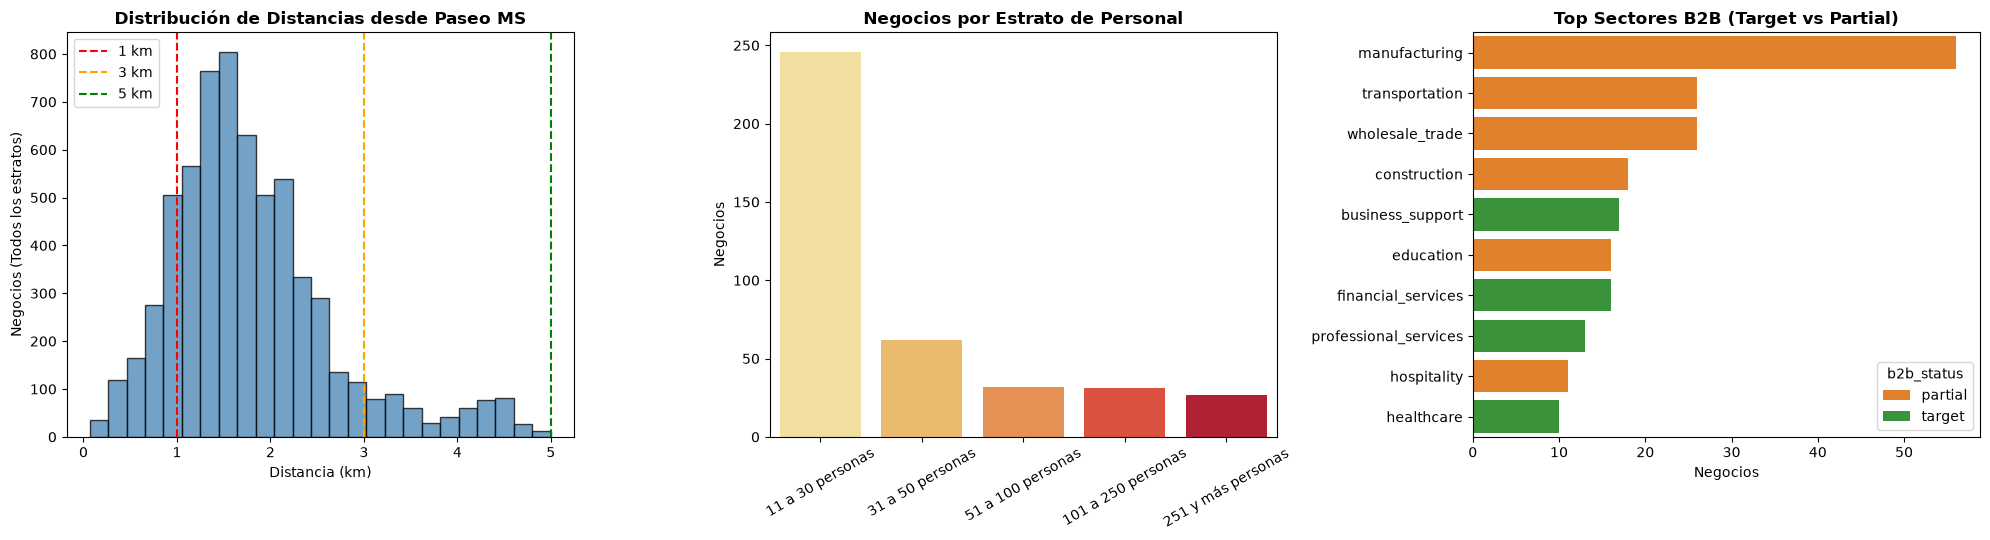

2026-10-24 21:21:24.966 | INFO     | __main__:create_b2b_osint_map:291 - ✅ Interactive 5D OSINT Map saved -> data/processed/b2b_5d_morning_transit_heatmap.html


In [9]:
# ═══════════════════════════════════════════════════════════════════════════
# END-TO-END OSINT PIPELINE EXECUTION, STAGE-02 HANDOFF & INTERACTIVE MAP
# ═══════════════════════════════════════════════════════════════════════════
from IPython.display import display

# 1. Ingest Official INEGI DENUE (or fallback to synthetic fixture if offline)
try:
    raw_zip = download_denue_state(settings.INEGI_STATE_CODE, settings.CACHE_DIR)
    raw_df = read_denue_csv(raw_zip)
except Exception as e:
    fallback_path = generate_synthetic_denue_fixture()
    logger.warning(f"Network ingest failed ({e}). Using synthetic fallback: {fallback_path}")
    raw_df = pl.read_parquet(fallback_path)

# 2. Vectorized Haversine Radius & Employee Strata Filtering
geo_df = filter_by_radius(raw_df, settings.TARGET_LAT, settings.TARGET_LON, settings.RADIUS_KM)
strata_df = filter_by_strata(geo_df, settings.MIN_EMPLOYEES_STRATA)

# 3. SCIAN B2B Qualification (Excluding public sector & food/bev retail)
qualified_df = qualify_b2b(strata_df)

# 4. SICT 7:00-10:00 AM Commute Corridors & Empirical INEGI/IMSS + CRITIC/AdaBoost Scoring
corridors_7_10am, traffic_nodes_7_10am = build_corridor_geometries()
empirical_df = enrich_empirical_income_and_scholarship(qualified_df, traffic_nodes_7_10am)
qualified_5d_df, learned_weights = calculate_critic_and_adaboost_weights(empirical_df)

# 5. ODbL-Isolated OpenStreetMap Amenities Layer
osm_df = query_osm_amenities(
    settings.TARGET_LAT,
    settings.TARGET_LON,
    settings.RADIUS_KM,
    cache_path=settings.PROCESSED_DIR / "osm_amenities.parquet",
)

# 6. Persist Stage-01 Processed Extract & Stage-02 Entity Resolution Handoff Parquet
proc_parquet_path, stage2_handoff_path = persist_stage1_extract(
    qualified_5d_df,
    settings.INEGI_STATE_CODE,
    settings.RADIUS_KM,
    settings.CACHE_DIR,
    settings.PROCESSED_DIR,
)

# Verify Stage-02 Handoff Contract for 02_entity_resolution.ipynb & 03_scoring_export.ipynb
_handoff_check = pl.read_parquet(stage2_handoff_path)
_required_stage2_cols = {"id", "clee", "nombre_estab", "raz_social", "codigo_act", "per_ocu", "lat", "lon", "distance_km", "b2b_5d_score"}
assert _required_stage2_cols.issubset(set(_handoff_check.columns)), f"Missing Stage-02 cols: {_required_stage2_cols - set(_handoff_check.columns)}"

# 7. Export Single Authoritative 5D Gold List CSV (Direct Targets + Rescued High-Wage Accounts with Email)
gold_5d_path = settings.PROCESSED_DIR / "b2b_gold_list_5d_morning.csv"
gold_5d_df = (
    qualified_5d_df.filter((pl.col("b2b_status") == "target") | pl.col("is_rescued_partial"))
    .filter(pl.col("email").is_not_null() & (pl.col("email") != ""))
    .select([
        "b2b_5d_score", "critic_objective_score", "adaboost_b2b_score",
        "business_name", "legal_name", "b2b_status", "is_rescued_partial",
        "est_monthly_wage_mxn", "est_degree_share", "est_monthly_payroll_mxn",
        "workforce_scholarship_tier", "b2b_sector", "employee_strata",
        "morning_traffic_score", "distance_km", "corridor_dist_km",
        "email", "phone", "website", "lat", "lon",
    ])
    .sort("b2b_5d_score", descending=True)
)
gold_5d_df.write_csv(gold_5d_path)

# 8. Consolidated Executive Summary, Top 15 Actionable Prospects & Diagnostic Charts
print_business_metrics(qualified_5d_df, learned_weights)
print(f"\n🏆 LISTA DE ORO 5D EXPORTADA: {len(gold_5d_df)} prospectos accionables con email -> {gold_5d_path}")
print(f"🔗 HANDOFF STAGE 02 LISTO:    {len(_handoff_check)} registros validados -> {stage2_handoff_path}")
print("\n🚀 TOP 15 PROSPECTOS PRIORITARIOS (SALARIO EMPÍRICO INEGI/IMSS + FLUJO SICT 7-10 AM + ENSEMBLE):")
for idx, r in enumerate(gold_5d_df.head(15).iter_rows(named=True), 1):
    tag = "🚀 RESCATADO" if r["is_rescued_partial"] else "✅ DIRECTO  "
    print(
        f" {idx:2d}. [{r['b2b_5d_score']:>4.2f} pts] {tag} | {r['business_name'][:32]:<32} | "
        f"${r['est_monthly_wage_mxn']:>6,.0f}/mes ({r['est_degree_share']*100:>2.0f}% Prof) | "
        f"Nómina: ${r['est_monthly_payroll_mxn']/1e6:>4.2f}M | Dist: {r['distance_km']:.2f}km"
    )

plot_summary_charts(geo_df, qualified_5d_df, settings.PROCESSED_DIR)

# 9. Build, Save & Display Unified Interactive Folium Map
b2b_osint_map = create_b2b_osint_map(
    qualified_5d_df,
    corridors_7_10am,
    traffic_nodes_7_10am,
    osm_df=osm_df,
    target_lat=settings.TARGET_LAT,
    target_lon=settings.TARGET_LON,
    output_path=settings.PROCESSED_DIR / "b2b_5d_morning_transit_heatmap.html",
)
display(b2b_osint_map)